# Demand Profile Methodology

This notebook demonstrates how the demand profile for the data center load (both compute and power demands) was created based on the available open source data and assumptions made.

In [1]:
#This is mounting through Colab
#Either route to the created directed accordingly or delete this cell altogether if running locally
#(Keep in mind that for local usage some of the packages may need to be additionally downloaded as Colab has some of the packages preinstalled)

# from google.colab import drive
# drive.mount('/content/drive')

# %cd /content/drive/MyDrive/Compute/

### Compute Demand

The first piece is the compute demand. We focus on the LLM inference serving, hence we establish demand based on token usage (or simply the amount of text processed) over a period of time (tokens per second).

LLM usage consists of two main parts: input of context (i.e., users sending prompts) and output generation (model serving the response). In compute, this is denotes as prefill and decode. We establish demand for both as output without input and vice versa does not have neither meaning nor value.

We use Azure 2024 dataset (https://github.com/Azure/AzurePublicDataset/blob/master/AzureLLMInferenceDataset2024.md) to generate a profile of the context and generated tokens across time.

We download both the conversation and coding dataset and read them accordingly.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt


azure_conv = pd.read_csv('AzureLLMInferenceTrace_conv_1week.csv')
azure_code = pd.read_csv('AzureLLMInferenceTrace_code_1week.csv')

Both of the datasets consist of the individual request data. The columns are the timestamp of the request arrival, with input (context) and output (generated) tokens.

In [3]:
azure_conv.head(n=2)

,TIMESTAMP,ContextTokens,GeneratedTokens
0,2024-05-12 00:00:00.001163+00:00,1452,3
1,2024-05-12 00:00:00.041683+00:00,584,3


In [4]:
azure_code.head(n=2)

,TIMESTAMP,ContextTokens,GeneratedTokens
0,2024-05-10 00:00:00.009930+00:00,2162,5
1,2024-05-10 00:00:00.017335+00:00,2399,6


We can take a look at the distribution of each of them. The code to run this can have the following look:



```
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create the distribution plot
sns.histplot(azure_code.GeneratedTokens, kde=True, bins=100, color="skyblue", label='generated tokens')
sns.histplot(azure_code.ContextTokens, kde=True, bins=100, color="lightcoral", label='context tokens')

# Add labels and display
plt.title("Token distribution for code dataset")
plt.xlabel("Values")
plt.ylabel("Frequency")
plt.legend()
plt.show()
```

Since there is a lot of data, the provided snippet enough is not efficient in a computational sense and can take a lot of time and RAM to render. The plots below are embedded in markdown as the result of the code above.



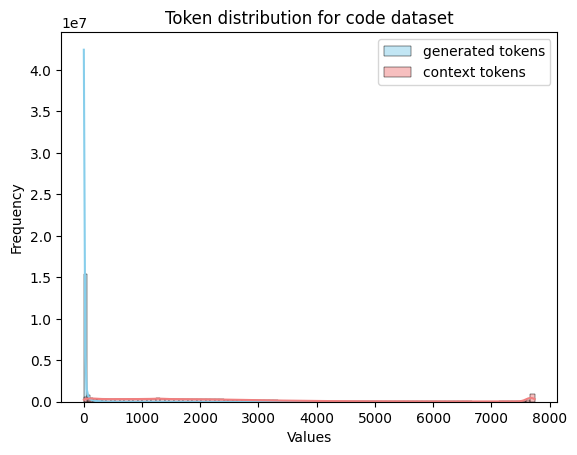

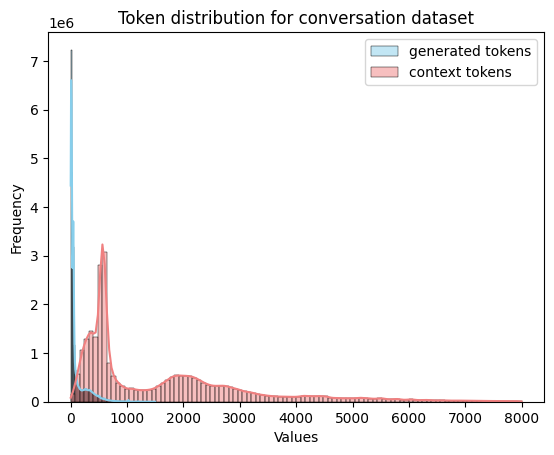

There are a few key observatons:


*   Conversation and code datasets have clearly different distributions, especialluy for the context tokens.
*   Context tokens have a huge spread and are longer compared to the generated tokens.
*   Generated tokens distribution is very skewed to 0.

This has a few implications for modeling. Firstly, despite the fact that input tokens do not require autoregressive generation and can be processed much more efficiently (from computational point of view), as the input tokens are large, they cannot be ignored. Hence, we choose to keep track of both demands from the dataset. Secondly, we construct a demand profile from both datasets as they pose some of the distributional differences.



We convert the timestamp to the datetime native format.

In [5]:
azure_code['Timestamp'] = pd.to_datetime(azure_code['TIMESTAMP'], format='mixed')
azure_conv['Timestamp'] = pd.to_datetime(azure_conv['TIMESTAMP'], format='mixed')

#TODO: Add rationale...


We do the following operations to create the profile:


*   We resample data on the 5-minute intervals with the idea of having clearing intervals similar to current operations of today's electricity markets.
*   We sum the tokens and requests across the 5-minute intervals.
*   We only sample weekdays to isolate differences in weekday and weekday behavior.
*   We divide requests by 300 to obtain requests per second (i.e., there are 300 seconds in 5 minutes)
*   We take the median across the weekdays.
*   We obtain 3 series: requests per second, input tokens per request, and output tokens per request.


In [6]:
import numpy as np

def profile(trace, start="2024-05-13", end="2024-05-18"):
    """Median day at 5-min resolution: requests/s, tokens/s and mean tokens per request."""
    r = trace.resample('5min', on='Timestamp')
    g = r[['ContextTokens', 'GeneratedTokens']].sum().assign(Requests=r.size())
    g = g[(g.index >= start) & (g.index < end)]
    m = g.groupby(g.index.time).median() / 300           # per second
    m['n_in']  = m.ContextTokens / m.Requests            # mean input tokens per request
    m['n_out'] = m.GeneratedTokens / m.Requests          # mean output tokens per request
    return m

demand_conv, demand_code = profile(azure_conv), profile(azure_code)
DEM = {'conv': demand_conv, 'code': demand_code}
RAW = {'conv': azure_conv, 'code': azure_code}

The plot of the obtained profiles is provided below. The observation is that the input and output tokens per request are relatively stable across the day. The requests per second however have clear daily deviations.

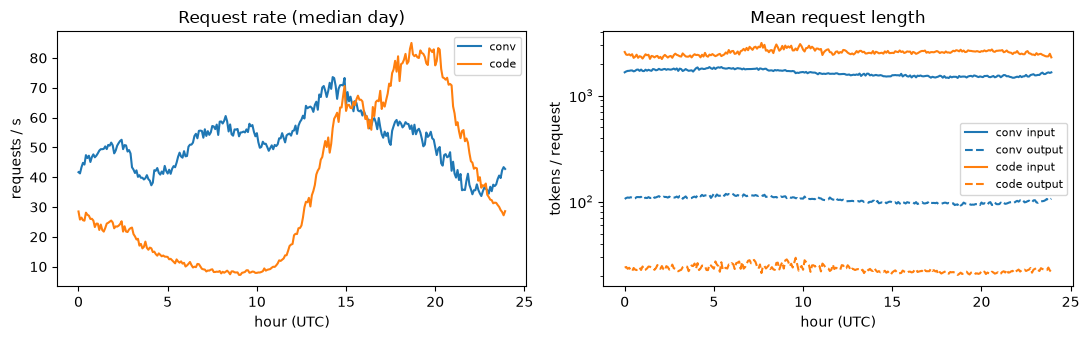

         conv    code
req/s    51.7    35.9
n_in   1632.7  2554.7
n_out   104.4    23.3


In [7]:
hours = np.arange(288) / 12
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i, (k, d) in enumerate(DEM.items()):
    ax[0].plot(hours, d.Requests, c=f'C{i}', label=k)
    ax[1].plot(hours, d.n_in, c=f'C{i}', label=f'{k} input')
    ax[1].plot(hours, d.n_out, '--', c=f'C{i}', label=f'{k} output')
ax[0].set(xlabel='hour (UTC)', ylabel='requests / s', title='Request rate (median day)')
ax[1].set(xlabel='hour (UTC)', ylabel='tokens / request', yscale='log', title='Mean request length')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(pd.DataFrame({k: [d.Requests.mean(), d.n_in.mean(), d.n_out.mean()] for k, d in DEM.items()},
                   index=['req/s', 'n_in', 'n_out']).round(1))

### Conversion to Power/Energy

We use ML.Energy dataset (https://huggingface.co/ml-energy) to link the power consumption and compute demand. We note that this is rather an approximation and conversion under several assumptions.

We first download the dataset through Hugging Face interface. Please obtain the necessary permission and HF token to obtain access.

In [8]:
# !pip install mlenergy-data
# from google.colab import userdata

# import os
# os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
import os

from dotenv import load_dotenv

load_dotenv()
assert os.getenv('HF_TOKEN')

from mlenergy.data.records import LLMRuns

c:\Users\16467\OneDrive\Desktop\Columbia\Research\Compute\ComputePricing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


We select choose the LLama 3.1-70B Instruct model on the H100 GPU. We show how the dataset looks like.

In [9]:
df = LLMRuns.from_hf().gpu_model('H100').architecture('Dense Transformer').to_dataframe()
MODEL, TASK = 'meta-llama/Llama-3.1-70B-Instruct', 'lm-arena-chat'

df = df[df["model_id"]==MODEL]
df = df[df['task']==TASK]

df.head(n=2)

,domain,task,model_id,nickname,architecture,total_params_billions,activated_params_billions,weight_precision,gpu_model,num_gpus,...,p50_itl_ms,p90_itl_ms,p95_itl_ms,p99_itl_ms,avg_batch_size,is_stable,unstable_reason,prompt_tokens,prefix_cache_queries,prefix_cache_hits
97,llm,lm-arena-chat,meta-llama/Llama-3.1-70B-Instruct,Llama 3.1 70B Instruct,Dense Transformer,70.0,70.0,bfloat16,H100,4,...,16.572714,16.908932,17.021280,21.116144,7.986667,True,,710590.0,710590.0,443552.0
98,llm,lm-arena-chat,meta-llama/Llama-3.1-70B-Instruct,Llama 3.1 70B Instruct,Dense Transformer,70.0,70.0,bfloat16,H100,4,...,17.697437,18.106622,18.409154,32.135710,15.953771,True,,710590.0,710590.0,442752.0


Columns of dataset:

In [10]:
df.columns

Index(['domain', 'task', 'model_id', 'nickname', 'architecture',
       'total_params_billions', 'activated_params_billions',
       'weight_precision', 'gpu_model', 'num_gpus', 'max_num_seqs', 'seed',
       'num_request_repeats', 'tensor_parallel', 'expert_parallel',
       'data_parallel', 'steady_state_energy_joules',
       'steady_state_duration_seconds', 'energy_per_token_joules',
       'energy_per_request_joules', 'output_throughput_tokens_per_sec',
       'request_throughput_req_per_sec', 'avg_power_watts',
       'total_output_tokens', 'completed_requests', 'avg_output_len',
       'mean_itl_ms', 'median_itl_ms', 'p50_itl_ms', 'p90_itl_ms',
       'p95_itl_ms', 'p99_itl_ms', 'avg_batch_size', 'is_stable',
       'unstable_reason', 'prompt_tokens', 'prefix_cache_queries',
       'prefix_cache_hits'],
      dtype='str')

The quantities that are not provided in the dataset but can be computed from provided data are output per GPU (in terms of generated tokens per second) and also power per GPU. We note that this is solely power during the output phase as the "energy_per_token_joules" column is defined as "Energy per output token (J)". We also multiply the power by a factor of 1.3 to account for other components (i.e., CPU and the rest of the rack) involved in the generation process. The factor of 1000 converts power to kW.

In [11]:
df["output_per_gpu"] = df["output_throughput_tokens_per_sec"]/df["num_gpus"] # tok/s/GPU
df["power_per_gpu"] = df["energy_per_token_joules"]*df["output_per_gpu"]*1.3/1000   # J/token * tok/s/GPU = J/s/GPU = W/GPU (add 1.3 overhead of CPU and other things)

One of the key aspects in compute is the concept of batching or simply saying whether we can process multiple requests at the same time. This is important as during the decode phase we generate one token at a time. If we can paralellize this process, we can utilize compute much more efficiently.

In the plot below, we show how intertoken latency (time to produce a token) on the x-axis depends on the outpur per GPU (generated tokens). We also mark the maximum batch size on the curve through markers.

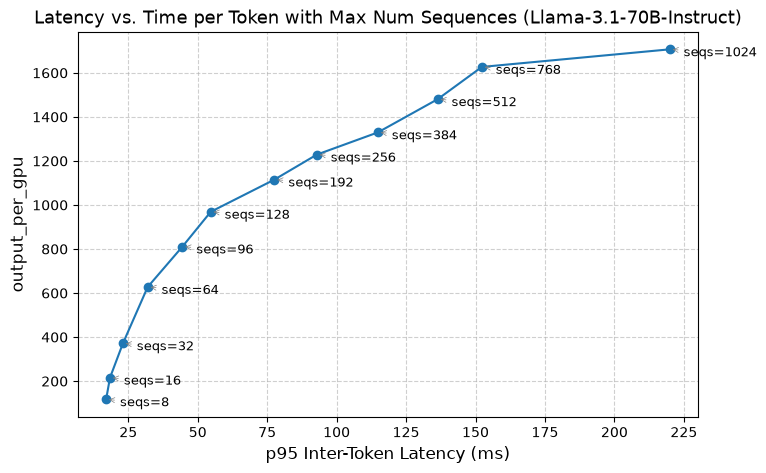

In [12]:
plt.figure(figsize=(8, 5))
x_vals = df["p95_itl_ms"]
y_vals = df["output_per_gpu"]

plt.plot(x_vals, y_vals, marker='o', linestyle='-', color='tab:blue', label='Throughput Curve')

for idx, row in df.iterrows():
    x = row["p95_itl_ms"]
    y = row["output_per_gpu"]
    label = int(row["max_num_seqs"])

    plt.annotate(f"seqs={label}",
                 (x, y),
                 textcoords="offset points",
                 xytext=(10, -5),
                 ha='left',
                 fontsize=9,
                 arrowprops=dict(arrowstyle="->", color='gray', lw=0.5))

plt.xlabel('p95 Inter-Token Latency (ms)', fontsize=12)
plt.ylabel('output_per_gpu', fontsize=12)
plt.title('Latency vs. Time per Token with Max Num Sequences (Llama-3.1-70B-Instruct)', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

We have the following observations:


*   The overall curve is non-linear. Initially, output rises much faster than latency, however it flattens out with larger batch size.
*   Larger batch size results in higher output but also in higher latency. This displays the fundamental trade-off: we can produce more with larger batch size but slower.

This has important implications related to user SLAs (service level agreements). SLAs can sometimes define user constraints in how quickly they want the generated response (this could also be related to user experience rather contracted quantity) in terms of latency. Hence, the constraint can limit operations only in a part of this curve.



We create the dataset with TP=4 (the only tensor parallelism offered in dataset).

In [13]:

TP = df.groupby('num_gpus').max_num_seqs.nunique().idxmax()   # TP size with the most batch sizes

d = df[df.num_gpus == TP]
d = d.groupby('max_num_seqs').mean(numeric_only=True).reset_index()   # one row per batch size

MODES = pd.DataFrame()
MODES['B']     = d.max_num_seqs                  # batch size: sequences running at once per replica
MODES['theta'] = d.output_per_gpu                # output tokens/s per GPU
MODES['pi_kw'] = d.power_per_gpu                 # kW per GPU, incl. 1.3 overhead
MODES['ell']   = d.p95_itl_ms                    # p95 time between tokens (ms): SLO check
MODES['itl_s'] = d.mean_itl_ms / 1000            # mean time between tokens (s): queue simulation
MODES['e']     = MODES.pi_kw * 1000 / MODES.theta   # J per output token
print(MODES.round(3))

       B     theta  pi_kw      ell  itl_s      e
0      8   117.422  0.574   17.021  0.017  4.886
1     16   215.662  0.586   18.409  0.018  2.718
2     32   371.667  0.583   23.068  0.021  1.569
3     64   627.628  0.650   31.987  0.025  1.036
4     96   811.085  0.683   44.494  0.029  0.842
5    128   969.067  0.710   54.682  0.032  0.732
6    192  1115.309  0.745   77.617  0.041  0.668
7    256  1228.776  0.765   92.885  0.049  0.623
8    384  1329.690  0.762  114.867  0.063  0.573
9    512  1480.325  0.810  136.371  0.079  0.547
10   768  1626.866  0.824  152.279  0.101  0.506
11  1024  1706.802  0.828  219.921  0.118  0.485


We construct the prefill (input token) energy separately using the results provided in the ML.Energy paper (https://arxiv.org/pdf/2505.06371). We leverage Table 4:
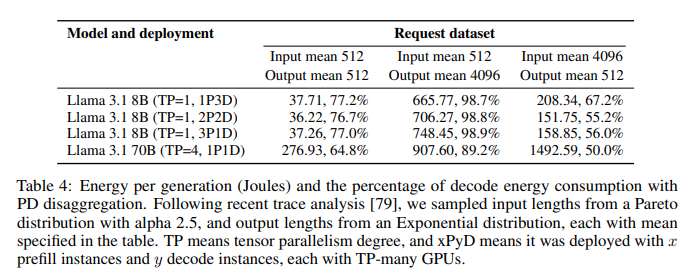


We construct the prefill throughput based on the hardware assumptions. From H100 specifications, the FLOPs for BF16 is 989.4 teraFLOPs (https://resources.nvidia.com/en-us-hopper-architecture/nvidia-h100-tensor-c - Table 1). BF16 also takes 2 bytes per parameter, and we also assume the MFU of 50%.

To find the energy per token, we use Table 4 entry to find the fraction spent on prefill and divide by the input length. We also use the same factor of 1.3 to account for other component usage.

In [14]:
PARAMS         = 70.6e9                          # Llama 3.1 70B
FLOP_PER_TOKEN = 2 * PARAMS                      # one multiply and one add per weight
H100_FLOPS     = 989.4e12                        # dense BF16 peak
MFU            = 0.50                            # share of peak reached in prefill (assumption)
THETA_PRE      = MFU * H100_FLOPS / FLOP_PER_TOKEN   # input tokens/s per GPU

# ML.ENERGY Table 4, Llama 3.1 70B: energy per request x prefill share / input tokens
E_PRE_GPU   = 276.93 * (1 - 0.648) / 512         # 512 in / 512 out  -> J per input token
E_PRE_CHECK = 1492.59 * (1 - 0.500) / 4096       # 4096 in / 512 out
E_PRE       = E_PRE_GPU * 1.3                    # same 1.3 overhead as decode

print(f'prefill throughput: {THETA_PRE:.0f} tok/s per GPU')
print(f'prefill energy: {E_PRE_GPU:.3f} J/token (check: {E_PRE_CHECK:.3f})')
print(f'implied prefill power: {E_PRE_GPU * THETA_PRE:.0f} W per GPU (H100 limit 700 W)')

prefill throughput: 3504 tok/s per GPU
prefill energy: 0.190 J/token (check: 0.182)
implied prefill power: 667 W per GPU (H100 limit 700 W)


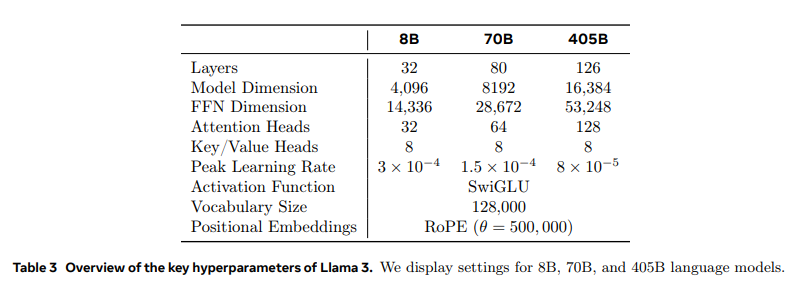

While we do not model the full serving pipeline of KVCache, we make an approximation based on the model parameters and HBM capacity for the maximum batch size that the model can serve.

We find the model specifications in the original paper (https://ai.meta.com/research/publications/the-llama-3-herd-of-models/, presented in the Table above). The head dimension is obtained by dividing the model dimension of (8192) by numbers of heads (64) to obtain the head dimension of 128. We also obtain the GPU memory capacity from the H100 specifications (https://www.nvidia.com/en-us/data-center/h100/). We calculate the available memory for 4 GPUs replica instance.

In [15]:
LAYERS, KV_HEADS, HEAD_DIM, BYTES = 80, 8, 128, 2               # Llama 3.1 70B config, bf16
KV_PER_TOKEN_GB = 2 * LAYERS * KV_HEADS * HEAD_DIM * BYTES / 1e9  # keys and values, all layers

HBM_GB      = 80                                 # memory per H100
WEIGHTS_GB  = 2 * PARAMS / 1e9                   # 2 bytes per parameter
KV_SPACE_GB = TP * HBM_GB * 0.9 - WEIGHTS_GB     # assume vLLM uses 90% of memory, and the rest is left for KV

print(f'KV per token: {KV_PER_TOKEN_GB * 1e3:.2f} MB, KV space per 4 GPUs: {KV_SPACE_GB:.0f} GB')
print(f'tokens that fit: {KV_SPACE_GB / KV_PER_TOKEN_GB:,.0f}')

KV per token: 0.33 MB, KV space per 4 GPUs: 147 GB
tokens that fit: 447,998


We create three theoretical classes of requests served which are primarily distinguished by the latency implications.

In [16]:
CLASSES = ['conversation', 'agentic', 'offline']
L_ITL   = {'conversation': 30, 'agentic': 50, 'offline': np.inf}          # ms, p95 ITL target
TRACE   = {'conversation': 'conv', 'agentic': 'code', 'offline': 'conv'}  # offline uses conv lengths (assumption)


We calculate the quantities according to the appropriate dataset.

In [17]:
REQ = pd.DataFrame(index=CLASSES)
for c in CLASSES:
    d = DEM[TRACE[c]]
    REQ.loc[c, 'n_in']  = d.ContextTokens.sum() / d.Requests.sum()     # mean input tokens per request
    REQ.loc[c, 'n_out'] = d.GeneratedTokens.sum() / d.Requests.sum()   # mean output tokens per request

We then calculate the maximum batch size that can served under the KVCache constraints. We use the following formula with the assumption:

$$B_{max} = \frac{M_{space}}{M_{token}(n_{in}+n_{out}/2)}$$

The assumption is that the output tokens are roughly twice shorter than the input tokens. This assumption is primarily drive by the observation made from the distribution plots.

In [18]:
REQ['B_max'] = KV_SPACE_GB / (KV_PER_TOKEN_GB * (REQ.n_in + REQ.n_out / 2))

We then calculate quantities for each of the class.

In [19]:
for c in CLASSES:
    ok = MODES[(MODES.ell <= L_ITL[c]) & (MODES.B <= REQ.B_max[c])]
    REQ.loc[c, 'mode'] = ok.theta.idxmax()
m = REQ['mode'].astype(int)
REQ['B']     = MODES.B[m].values
REQ['theta'] = MODES.theta[m].values
REQ['itl_s'] = MODES.itl_s[m].values

REQ['a'] = REQ.n_in / THETA_PRE + REQ.n_out / REQ.theta              # GPU-seconds per request
REQ['e'] = REQ.n_in * E_PRE + REQ.n_out * MODES.e[m].values          # J per request
print(REQ.round(3))

                  n_in    n_out    B_max  mode    B     theta  itl_s      a  \
conversation  1627.749  104.088  266.698   2.0   32   371.667  0.021  0.745   
agentic       2551.069   22.317  174.847   4.0   96   811.085  0.029  0.756   
offline       1627.749  104.088  266.698   7.0  256  1228.776  0.049  0.549   

                    e  
conversation  566.185  
agentic       650.198  
offline       467.693  


### Headroom (Optional)

Since we did the 5-minute approximation, we need to make a certain reassurance that we have enough installed hardware to serve requests at any point of time (the bursts in between are potentially smoothed out by averaging). This is done by providing headroom, which can serve the spikes.

[Note: while this is more or less standard practice in sizing queued requests, we make this section optional as we draw multiple assumptions as well pose limited analysis. In a big picture, our compute pricing will surge primarily from outages and similar external factors. We assume that the system is sized properly. ]

We treat each serving pool as a queue: requests arrive, wait for a free slot (a place in a GPU batch), process it, and then leave.


To calculate how long the request occupies the GPU slot, we use the following formula:

$$
s_i = \underbrace{\frac{\text{input tokens}_i}{TP \cdot \theta_{\text{pre}}}}_{\text{prefill}}
\;+\; \underbrace{\text{output tokens}_i \cdot \text{ITL}}_{\text{decode}}
$$

where $\theta_{\text{pre}}$ is prefill throughput per GPU, $TP$ the GPUs per replica (4 in this case), and ITL the time per generated token.

We then calculate how many slots on average have been occupied:

$$
L = \frac{1}{T}\sum_i s_i \qquad \big(= \text{arrival rate} \times \text{average service time}\big)
$$

This is the minimum capacity needed on average. Converted to GPUs: $\;\text{GPUs} = \dfrac{L}{B}\cdot TP$, with $B$ slots per 4 GPUs.

The overall capacity, given the headroom $\rho$, is then calculated as:

$$
S = \left\lceil \frac{L}{\rho} \right\rceil
$$

We sweep different values of $\rho$ to access the waiting time implied from the data.

For each request in arrival order, with $a_i$ its arrival time and $f_k$ the time slot $k$ becomes free:

$$
\text{start}_i = \max\!\big(a_i,\; \min_k f_k\big), \qquad
w_i = \text{start}_i - a_i, \qquad
f_k \leftarrow \text{start}_i + s_i
$$

We then calculate how many requests have been processed on time:

$$
\text{on-time}(\rho) = \frac{\#\{\,i : w_i \le W\,\}}{N}
$$

with $W$ = 1 s (conversation) or 10 s (agentic).

We then pick the maximum values that meets the target:

$$
\bar\rho = \max\{\rho : \text{on-time}(\rho) \ge 0.95\}
$$

We assume that offline traffic has no waiting target, so it runs at $\bar\rho = 0.95$.

For the actual implementation, we follow the procedure above using the following assumptions and implementation:


*   We pick the 4 weekday days from the dataset. We find the peak of requests/second for each of them and find the 30-minute of +-15 minutes from the peak.
*   We find the headroom that meets the target for each of those days.
*   We pick the minimum headroom as for the worst day and maximum demand. 



conversation 2024-05-13: 66,501 requests, 165 busy slots = 21 GPUs, rho_bar = 0.9
conversation 2024-05-14: 68,117 requests, 165 busy slots = 21 GPUs, rho_bar = 0.85
conversation 2024-05-15: 65,249 requests, 158 busy slots = 20 GPUs, rho_bar = 0.9
conversation 2024-05-16: 61,926 requests, 154 busy slots = 19 GPUs, rho_bar = 0.85
conversation: rho_bar per day = [0.9, 0.85, 0.9, 0.85] -> using 0.85

agentic 2024-05-13: 67,788 requests, 60 busy slots = 3 GPUs, rho_bar = 0.98
agentic 2024-05-14: 77,542 requests, 68 busy slots = 3 GPUs, rho_bar = 0.99
agentic 2024-05-15: 76,369 requests, 67 busy slots = 3 GPUs, rho_bar = 0.99
agentic 2024-05-16: 72,579 requests, 64 busy slots = 3 GPUs, rho_bar = 0.99
agentic: rho_bar per day = [0.98, 0.99, 0.99, 0.99] -> using 0.98



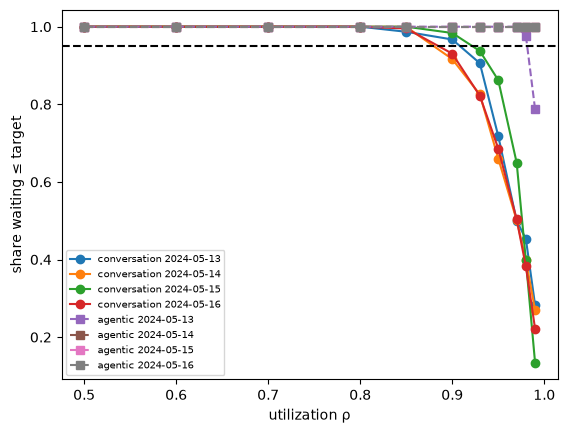

{'offline': 0.95, 'conversation': 0.85, 'agentic': 0.98}


In [20]:
RHO  = {'offline': 0.95}                          # offline has no waiting target
WAIT = {'conversation': 1.0, 'agentic': 10.0}     # s, waiting-time target per class
MINUTES = 15                                      # window length (min)
T = MINUTES * 60                                  # window length (s)
DAYS = ['2024-05-13', '2024-05-14', '2024-05-15', '2024-05-16']   # weekdays in both traces
RHO_GRID = [0.99, 0.98, 0.97, 0.95, 0.93, 0.9, 0.85, 0.8, 0.7, 0.6, 0.5]

for c in ['conversation', 'agentic']:
    peak_time = DEM[TRACE[c]].Requests.idxmax()   # time of day with the most requests
    x = RAW[TRACE[c]]
    rho_per_day = []

    for day in DAYS:
        # requests arriving in the peak window of this day
        start = pd.Timestamp.combine(pd.Timestamp(day).date(), peak_time).tz_localize('UTC')
        w = x[(x.Timestamp >= start) & (x.Timestamp < start + pd.Timedelta(minutes=MINUTES))]
        w = w.sort_values('Timestamp')
        arrival = (w.Timestamp - start).dt.total_seconds().values         # s since window start
        service = w.ContextTokens.values / (TP * THETA_PRE) + w.GeneratedTokens.values * REQ.itl_s[c]   # s a request holds one slot
        load = service.sum() / T                                          # average busy slots

        on_time = []
        for rho in RHO_GRID:
            S = int(np.ceil(load / rho))          # slots provisioned at this utilization
            free_at = np.zeros(S)                 # time at which each slot becomes free
            wait = np.zeros(len(arrival))
            for i in range(len(arrival)):
                k = np.argmin(free_at)            # slot that frees up first
                begin = max(arrival[i], free_at[k])
                wait[i] = begin - arrival[i]
                free_at[k] = begin + service[i]
            on_time.append(np.mean(wait <= WAIT[c]))

        sweep = pd.DataFrame({'rho': RHO_GRID, 'on_time': on_time})
        rho_day = sweep[sweep.on_time >= 0.95].rho.max()   # highest utilization that meets the target
        rho_per_day.append(rho_day)
        print(f'{c} {day}: {len(arrival):,} requests, {load:.0f} busy slots '
              f'= {load / REQ.B[c] * TP:.0f} GPUs, rho_bar = {rho_day}')
        plt.plot(sweep.rho, sweep.on_time, 'o-' if c == 'conversation' else 's--', label=f'{c} {day}')

    RHO[c] = min(rho_per_day)                     # worst day sets the utilization
    print(f'{c}: rho_bar per day = {rho_per_day} -> using {RHO[c]}\n')

plt.axhline(0.95, c='k', ls='--'); plt.xlabel('utilization ρ'); plt.ylabel('share waiting ≤ target')
plt.legend(fontsize=7); plt.show()
print(RHO)

#TODO: Add a bit of queuering theory discussion

### Total Demand




We size the sites from their power budget, shape demand over the day, and scale demand so that its peak fills the installed GPUs.

The power of one GPU of full load is the following:

$$
P_{\text{GPU}} = \max\big(\,P_{\text{decode}},\; e_{\text{pre}} \cdot \theta_{\text{pre}}\,\big)
$$

Hence, we size for the worst case.

We assume a capacity of the data center as $MW_{s}$ and find the number of GPUs accordingly:

$$
G_s = \left\lfloor \frac{\text{MW}_s}{\text{PUE}_s \cdot P_{\text{GPU}}} \right\rfloor
$$

Site power is split between IT and overhead (cooling etc.) by the PUE, and the IT part is divided by the power of one GPU.

We find the daily shape for each of the class to have the daily profile:

$$
f_c(t) = \frac{\text{requests}_c(t)}{\max_t \text{requests}_c(t)}
$$

The median-day request rate from the trace, normalized so the peak is 1. Offline work is flat: $f_{\text{offline}}(t) = 1$.

We then construct demand per region and per class:

$$
d_{r,c}(t) = \text{share}_r \cdot \text{mix}_c \cdot f_c(t - \text{shift}_r)
$$

A region's share of total demand × the class's share of requests × the daily shape, delayed by the region's time-zone shift.

The GPUs needed per request per second are:

$$
a_c = \frac{n^{\text{in}}_c}{\theta_{\text{pre}}} + \frac{n^{\text{out}}_c}{\theta_c},
\qquad
g_c = \frac{a_c}{\rho_c}
$$

$a_c$ is the GPU-seconds one request takes: prefill time plus decode time. Dividing by the utilization $\rho_c$ adds the headroom needed for the waiting-time target. By Little's law (requests per second × seconds per request = busy GPUs), a demand of $\lambda$ requests/s needs $\lambda\, g_c$ GPUs.

The Total GPU need over the day:

$$
\text{need}(t) = \sum_{r}\sum_{c} d_{r,c}(t)\; g_c
$$

We scale demand to the installed fleet:

$$
k = \frac{\text{UTIL} \cdot \sum_s G_s}{\max_t \text{need}(t)},
\qquad
\lambda_{r,c}(t) = k \, d_{r,c}(t)
$$

The demand is scaled so that at the busiest moment the fleet is UTIL (90%) full. $\lambda$ is in requests per second. Sizing uses the **total** fleet, so a region may need more GPUs than its own site has; routing between sites is left to the clearing model.

The tokens and IT power:

$$
\text{tokens}^{\text{in}}_{r,c}(t) = \lambda_{r,c}(t)\, n^{\text{in}}_c,
\qquad
\text{tokens}^{\text{out}}_{r,c}(t) = \lambda_{r,c}(t)\, n^{\text{out}}_c
$$

$$
e_c = n^{\text{in}}_c\, e_{\text{pre}} + n^{\text{out}}_c\, e^{\text{decode}}_c,
\qquad
P^{\text{IT}}_{r,c}(t) = \frac{\lambda_{r,c}(t)\; e_c}{10^6}
$$

Energy per request (J) × requests per second = W, divided by $10^6$ to get MW. This is the IT load of busy GPUs only; site PUE is applied later.

In [21]:
#Make headroom optional
#If headroom is set to 1, the code will not modify RHO. 
#If headroom is set to any other value, RHO will be set to an array of ones with the same length as RHO.

USE_HEADROOM = True                 # False: size for average load, with no queueing headroom
if not USE_HEADROOM:
    RHO = {c: 1.0 for c in CLASSES}



In [22]:
MIX     = {'conversation': .5, 'agentic': .3, 'offline': .2}   # share of requests per class (assumption)
SHIFT   = [0, 1, 2]                                           # hours of time-zone shift per region
SHARE   = [.5, .3, .2]                                        # region share of total demand
SITE_MW = np.array([25., 25., 25.])
PUE     = np.array([1.2, 1.2, 1.35])
UTIL    = 0.90                                                # peak GPU need / installed GPUs

P_GPU  = max(MODES.pi_kw.max(), E_PRE * THETA_PRE / 1e3)      # kW per GPU at max draw (decode or prefill)
G_SITE = np.floor(SITE_MW * 1e3 / (PUE * P_GPU)).astype(int)

SHAPE = {'conversation': demand_conv.Requests.values, 'agentic': demand_code.Requests.values, 'offline': np.ones(288)}
SHAPE = {c: v / v.max() for c, v in SHAPE.items()}            # 24h profile, peak = 1
DC_unit = np.array([[SHARE[r] * MIX[c] * np.roll(SHAPE[c], SHIFT[r] * 12) for c in CLASSES]
                    for r in range(3)])                       # [region, class, t]

gpu_per_req = np.array([REQ.a[c] / RHO[c] for c in CLASSES])  # GPUs per req/s (busy + headroom)
need = np.einsum('rct,c->t', DC_unit, gpu_per_req)
DC = DC_unit * UTIL * G_SITE.sum() / need.max()               # requests/s [region, class, t]

n_in, n_out, e_req = (REQ[k].values[None, :, None] for k in ['n_in', 'n_out', 'e'])
TOK_IN, TOK_OUT = DC * n_in, DC * n_out                       # tokens/s
P_IT = DC * e_req / 1e6                                       # MW of busy IT load (before PUE, which depends on site)
print('GPUs per site:', G_SITE, '| peak req/s:', DC.sum((0, 1)).max().round(0),
      '| peak IT MW:', P_IT.sum((0, 1)).max().round(1))

GPUs per site: [24025 24025 21355] | peak req/s: 79893.0 | peak IT MW: 45.4


We plot the resulting demand:

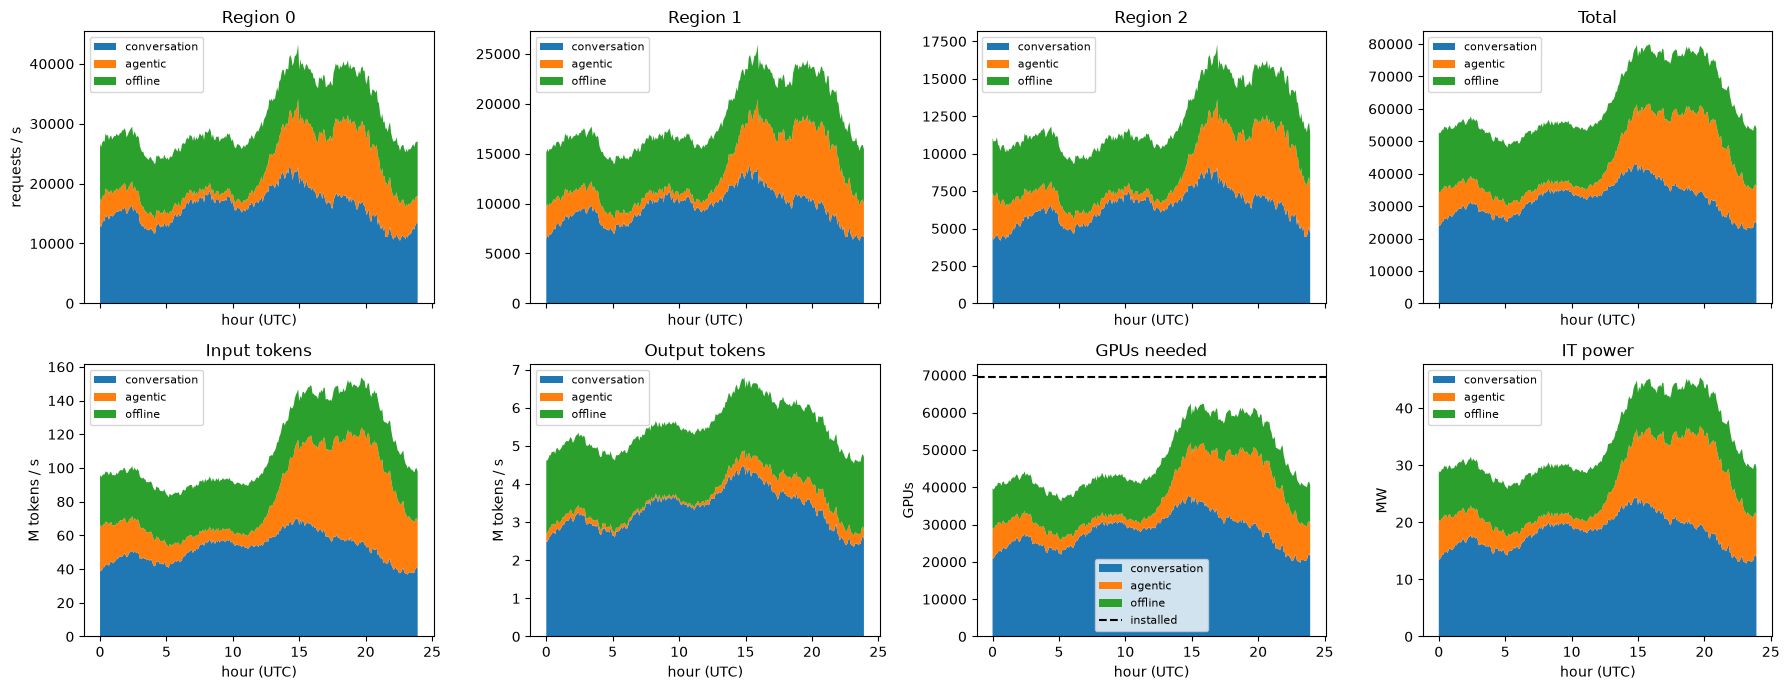

In [23]:
# fig, ax = plt.subplots(1, 4, figsize=(18, 3.5), sharey=True)
# for r in range(3):
#     ax[r].stackplot(hours, DC[r], labels=CLASSES); ax[r].set_title(f'Region {r}')
# ax[3].stackplot(hours, DC.sum(0), labels=CLASSES); ax[3].set_title('Total'); ax[3].legend(fontsize=8)
# ax[0].set_ylabel('requests / s')
# for a in ax: a.set_xlabel('hour (UTC)')
# plt.tight_layout(); plt.show()

# gpus = DC.sum(0) * gpu_per_req[:, None]                       # [class, t] busy + headroom GPUs
# fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
# ax[0].stackplot(hours, TOK_IN.sum(0) / 1e6, labels=CLASSES);  ax[0].set(title='Input tokens', ylabel='M tokens / s')
# ax[1].stackplot(hours, TOK_OUT.sum(0) / 1e6, labels=CLASSES); ax[1].set(title='Output tokens', ylabel='M tokens / s')
# ax[2].stackplot(hours, gpus, labels=CLASSES); ax[2].axhline(G_SITE.sum(), c='k', ls='--', label='installed')
# ax[2].set(title='GPUs needed', ylabel='GPUs')
# ax[3].stackplot(hours, P_IT.sum(0), labels=CLASSES);          ax[3].set(title='IT power', ylabel='MW')
# for a in ax: a.set_xlabel('hour (UTC)'); a.legend(fontsize=8)
# plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(18, 7), sharex=True)

# Row 1: Requests per second by region and total
for r in range(3):
    ax[0, r].stackplot(hours, DC[r], labels=CLASSES)
    ax[0, r].set_title(f'Region {r}')

ax[0, 3].stackplot(hours, DC.sum(0), labels=CLASSES)
ax[0, 3].set_title('Total')

ax[0, 0].set_ylabel('requests / s')

# Calculate GPU requirements
gpus = DC.sum(0) * gpu_per_req[:, None]

# Row 2: Aggregate system metrics
ax[1, 0].stackplot(hours, TOK_IN.sum(0) / 1e6, labels=CLASSES)
ax[1, 0].set(title='Input tokens', ylabel='M tokens / s')

ax[1, 1].stackplot(hours, TOK_OUT.sum(0) / 1e6, labels=CLASSES)
ax[1, 1].set(title='Output tokens', ylabel='M tokens / s')

ax[1, 2].stackplot(hours, gpus, labels=CLASSES)
ax[1, 2].axhline(G_SITE.sum(), c='k', ls='--', label='installed')
ax[1, 2].set(title='GPUs needed', ylabel='GPUs')

ax[1, 3].stackplot(hours, P_IT.sum(0), labels=CLASSES)
ax[1, 3].set(title='IT power', ylabel='MW')

# Formatting
for a in ax.flat:
    a.set_xlabel('hour (UTC)')
    a.legend(fontsize=8)

plt.tight_layout()
plt.show()


In [24]:
t = gpus.sum(0).argmax()                                     # peak GPU-need interval
need_pk = gpus[:, t].sum()                                   # GPUs needed, incl. headroom
busy_pk = (DC.sum(0)[:, t] * REQ.a.values).sum()             # busy GPUs
it_pk   = P_IT[:, :, t].sum()                                # MW

print(f'Max at full draw: {need_pk * P_GPU / 1e3:.1f} MW')
print(f'After removing headroom: {busy_pk * P_GPU / 1e3:.1f} MW')
print(f'Actual busy IT power: {it_pk:.1f} MW')
print(f'Average draw per busy GPU: {it_pk * 1e3 / busy_pk:.3f} kW')

Max at full draw: 54.2 MW
After removing headroom: 48.6 MW
Actual busy IT power: 44.9 MW
Average draw per busy GPU: 0.801 kW


In [25]:
import json

PI0_KW = 0.12   # kW per idle GPU, incl. overhead (TODO: add source)

MODES.to_csv('modes.csv')
REQ[['n_in', 'n_out', 'B_max']].to_csv('request_coefficients.csv')
np.save('demand_req_s.npy', DC.reshape(3, 3, 24, 12).mean(axis=3))   # req/s [region, class, hour]
json.dump({'THETA_PRE': THETA_PRE, 'E_PRE': E_PRE, 'PI0_KW': PI0_KW, 'RHO': RHO, 'L_ITL': L_ITL,
           'SITE_MW': SITE_MW.tolist(), 'PUE': PUE.tolist(), 'G_SITE': G_SITE.tolist()},
          open('demand_params.json', 'w'), indent=2)

In [26]:
print(REQ[['n_in', 'n_out']].round(0))

                n_in  n_out
conversation  1628.0  104.0
agentic       2551.0   22.0
offline       1628.0  104.0


In [28]:
print(REQ['n_in']/REQ['n_out'])

conversation     15.638235
agentic         114.312922
offline          15.638235
dtype: float64


In [27]:
# Observation: input tokens dominate the token count, but output tokens dominate GPU time and energy.

# %% 9. Export for the clearing model -------------------------------------------
# idx = pd.MultiIndex.from_product([range(3), CLASSES, range(288)], names=['region', 'cls', 't'])
# pd.DataFrame({'req_s': DC.ravel(), 'in_tok_s': TOK_IN.ravel(),
#               'out_tok_s': TOK_OUT.ravel(), 'it_mw': P_IT.ravel()}, index=idx).to_csv('demand_profile.csv')
# REQ.to_csv('request_coefficients.csv')

### Acknowledgements

The authors disclose the use of Anthropic Claude to conduct this work. The usage included assistance in writing, literature review, methodology refinement, and code generation and editing. Conceptual ideas, experimental design, implementations, analyses, and conclusions are the authors’ own. The authors take responsibility for all mistakes.